In [1]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import brier_score_loss
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bootstrap

In [2]:
df_features = pd.read_csv('features/features_regimes_week4.csv')
df_target = pd.read_csv('targets/weather_regimes_target.csv')

In [3]:
df_features['time'] = pd.to_datetime(df_features['time'])
df_features = df_features.set_index('time')

df_target['time'] = pd.to_datetime(df_target['time'])
df_target = df_target.set_index('time')

In [4]:
y_train = df_target[df_target.index < "2010-07"].values[:,0]
y_test = df_target[df_target.index >= "2010-07"].values[:,0]

In [5]:
drop = ['nino3.4_index', 'siberian_snow', 'sea_ice_arctic', 'st100_index', 'MJO_phase', 'sea_ice_baka']
df_features_sel = df_features.drop(columns=drop)
len(df_features_sel.columns)

2

In [6]:
X_train = df_features_sel[df_features_sel.index < "2010-07"].values
X_test = df_features_sel[df_features_sel.index >= "2010-07"].values

In [7]:
y_climpred = np.zeros((15*84, 4))
for i in range(4):
    y_climpred[:, i] = np.count_nonzero(y_train == i)/len(y_train)

y_climpred

array([[0.22757937, 0.25416667, 0.29543651, 0.22281746],
       [0.22757937, 0.25416667, 0.29543651, 0.22281746],
       [0.22757937, 0.25416667, 0.29543651, 0.22281746],
       ...,
       [0.22757937, 0.25416667, 0.29543651, 0.22281746],
       [0.22757937, 0.25416667, 0.29543651, 0.22281746],
       [0.22757937, 0.25416667, 0.29543651, 0.22281746]], shape=(1260, 4))

In [8]:
y_climpred_valid = np.zeros((60*84, 4))
for i in range(4):
    y_climpred_valid[:, i] = np.count_nonzero(y_train == i)/len(y_train)

brier_score_loss(y_train, y_climpred_valid)

0.7466765873015871

In [9]:
classifier = RandomForestClassifier(n_estimators=1000, criterion='entropy', max_depth=None, min_samples_leaf=800, random_state=42)
classifier.fit(X_train, y_train)

y_pred = classifier.predict_proba(X_test)

bs_ann = np.zeros(15)
bs_clim_ann = np.zeros(15)
y_pred_ann = y_pred.reshape((15,84,4))
y_climpred_ann = y_climpred.reshape((15,84,4))
y_test_ann = y_test.reshape((15,84))
for i in range(15):
    bs_ann[i] = brier_score_loss(y_test_ann[i], y_pred_ann[i], labels=[0,1,2,3])
    bs_clim_ann[i] = brier_score_loss(y_test_ann[i], y_climpred_ann[i], labels=[0,1,2,3])

print(bs_ann.mean())
print(bs_clim_ann.mean())

0.7349189689974501
0.7399239417989416


In [10]:
y_pred.mean(axis=0)

array([0.21022086, 0.26480105, 0.30439114, 0.22058694])

In [11]:
bss = 100*(1-bs_ann.mean()/bs_clim_ann.mean())
print(bss)

0.676417198951984


In [2]:
bs_valid = 0.7443027821826964
bss_valid = 100*(1-bs_valid/0.7466765873015871)
print(bss_valid)

0.31791610440999873


In [3]:
bs_valid_clim = 0.750627033905905
bss_valid_unbiased = 100*(1-bs_valid/bs_valid_clim)
print(bss_valid_unbiased)

0.8425291706188887


In [13]:
def skill_score(score, ref_score, axis=-1):
    mean = np.mean(score, axis=axis)
    mean_ref = np.mean(ref_score, axis=axis)
    return 1 - mean/mean_ref

In [14]:
skill_score(bs_ann, bs_clim_ann)

np.float64(0.0067641719895198404)

In [15]:
res = bootstrap((bs_ann, bs_clim_ann), skill_score, paired=True, confidence_level=0.90, rng=42)

In [16]:
res.confidence_interval

ConfidenceInterval(low=np.float64(-0.005735576949397778), high=np.float64(0.018984768767128877))

In [17]:
lofo_bs = np.array([0.750118655746382, 0.7453724277489789])
lofo_importances = lofo_bs - bs_valid
df_importances = pd.Series(
    lofo_importances, index=df_features_sel.columns
)

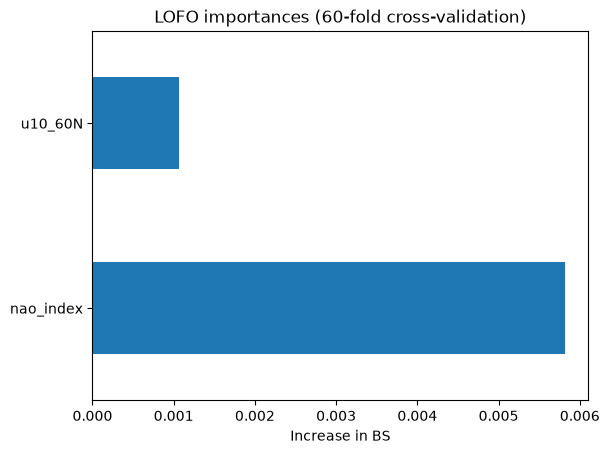

In [18]:
ax = df_importances.plot.barh()
ax.set_title("LOFO importances (60-fold cross-validation)")
ax.set_xlabel("Increase in BS")
plt.savefig('regimes_lofo_valid_week4.png', bbox_inches = 'tight')

In [19]:
lofo_bs_test = np.zeros(2)
for i in range(2):

    leave_out = df_features_sel.columns[i]
    df_features_new = df_features_sel.drop(columns=leave_out)
    X_train = df_features_new[df_features_new.index < "2010-07"].values
    X_test = df_features_new[df_features_new.index >= "2010-07"].values
    
    classifier = RandomForestClassifier(n_estimators=1000, criterion='entropy', max_depth=None, min_samples_leaf=800, random_state=42)
    classifier.fit(X_train, y_train)

    y_pred = classifier.predict_proba(X_test)
    bs = brier_score_loss(y_test, y_pred)
    lofo_bs_test[i] = bs

In [20]:
lofo_importances_test = lofo_bs_test - 0.7349189689974501
df_importances_test = pd.Series(
    lofo_importances_test, index=df_features_sel.columns
)

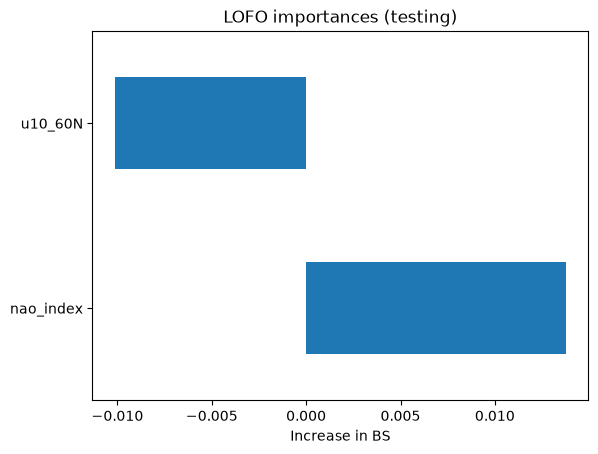

In [21]:
ax = df_importances_test.plot.barh()
ax.set_title("LOFO importances (testing)")
ax.set_xlabel("Increase in BS")
plt.savefig('regimes_lofo_test_week4.png', bbox_inches = 'tight')